In [1]:
import sys
sys.path.append("..")

import numpy as np
from sklearn.dummy import DummyClassifier

from src.data import load_raw, clean, split_by_month, feature_frame, LABEL
from src.metrics import evaluate
from src.tracking import setup, log_run

df = clean(load_raw("../data/Base.csv"))
train, valid, test = split_by_month(df)   # the test set is never used in this notebook

In [2]:
perfect = evaluate(valid[LABEL], valid[LABEL].astype(float))
print({k: round(v, 4) for k, v in perfect.items()})

{'pr_auc': 1.0, 'recall_at_fpr_5pct': 1.0, 'recall_at_fpr_1pct': 1.0, 'recall_at_top_1pct': 0.8455, 'recall_at_top_5pct': 1.0, 'brier': 0.0}


In [3]:
setup()

X_train, y_train = feature_frame(train), train[LABEL]
X_valid, y_valid = feature_frame(valid), valid[LABEL]

model = DummyClassifier(strategy="prior").fit(X_train, y_train)
score = model.predict_proba(X_valid)[:, 1]
metrics = evaluate(y_valid, score)
print({k: round(v, 4) for k, v in metrics.items()})

log_run(
    "dummy_prior",
    params={
        "model": "DummyClassifier(prior)",
        "train_months": "0-4",
        "eval_split": "validation (month 5)",
        "n_features": X_train.shape[1],
        "days_since_request_included": False,
    },
    metrics={f"valid_{k}": v for k, v in metrics.items()},
)

{'pr_auc': 0.0118, 'recall_at_fpr_5pct': 0.0454, 'recall_at_fpr_1pct': 0.0092, 'recall_at_top_1pct': 0.0092, 'recall_at_top_5pct': 0.0454, 'brier': 0.0117}


In [4]:
import pandas as pd

base = train[LABEL].mean()
cands = {
    "prev_address_missing": train["prev_address_months_count_missing"] == 1,
    "bank_months_missing": train["bank_months_count_missing"] == 1,
    "balcon_missing": train["intended_balcon_amount_missing"] == 1,
    "age_50_plus": train["customer_age"] >= 50,
    "free_email": train["email_is_free"] == 1,
    "home_phone_invalid": train["phone_home_valid"] == 0,
    "mobile_phone_invalid": train["phone_mobile_valid"] == 0,
    "no_other_cards": train["has_other_cards"] == 0,
    "foreign_request": train["foreign_request"] == 1,
    "no_keep_alive": train["keep_alive_session"] == 0,
    "teleapp_source": train["source"] == "TELEAPP",
    "low_name_email_sim": train["name_email_similarity"] < train["name_email_similarity"].quantile(0.10),
}
rows = [(n, m.mean(), train.loc[m, LABEL].mean(), train.loc[~m, LABEL].mean()) for n, m in cands.items()]
out = pd.DataFrame(rows, columns=["rule", "share_of_rows", "fraud_if_true", "fraud_if_false"])
out["lift"] = out["fraud_if_true"] / base
print(f"training fraud rate: {base:.4%}")
print(out.sort_values("lift", ascending=False).round(4).to_string(index=False))

training fraud rate: 0.9975%
                rule  share_of_rows  fraud_if_true  fraud_if_false   lift
         age_50_plus         0.1902         0.0220          0.0072 2.2045
     foreign_request         0.0263         0.0191          0.0097 1.9175
  low_name_email_sim         0.1000         0.0183          0.0091 1.8308
       no_keep_alive         0.4350         0.0155          0.0057 1.5511
 bank_months_missing         0.2550         0.0148          0.0083 1.4884
      teleapp_source         0.0075         0.0144          0.0099 1.4434
mobile_phone_invalid         0.1198         0.0144          0.0094 1.4421
prev_address_missing         0.6955         0.0131          0.0028 1.3163
          free_email         0.5463         0.0123          0.0072 1.2287
  home_phone_invalid         0.6131         0.0123          0.0064 1.2286
      balcon_missing         0.7308         0.0119          0.0048 1.1904
      no_other_cards         0.7846         0.0116          0.0039 1.1670


In [5]:
setup()
thr_sim = train["name_email_similarity"].quantile(0.10)   # threshold comes from TRAIN only

def flags(d, with_age):
    f = pd.DataFrame({
        "prev_address_missing": d["prev_address_months_count_missing"] == 1,
        "no_other_cards": d["has_other_cards"] == 0,
        "no_keep_alive": d["keep_alive_session"] == 0,
        "low_name_email_sim": d["name_email_similarity"] < thr_sim,
        "foreign_request": d["foreign_request"] == 1,
    })
    if with_age:
        f["age_50_plus"] = d["customer_age"] >= 50
    return f.astype(int)

def rules_score(with_age):
    n_tr = flags(train, with_age).sum(axis=1)
    table = train[LABEL].groupby(n_tr).mean()            # fraud rate per number of red flags, TRAIN only
    n_va = flags(valid, with_age).sum(axis=1)
    return n_va.map(table).fillna(train[LABEL].mean()).to_numpy(), table

for with_age in (False, True):
    name = "rules_with_age" if with_age else "rules_no_age"
    score, table = rules_score(with_age)
    m = evaluate(valid[LABEL], score)
    print(name, {k: round(v, 4) for k, v in m.items()})
    print("train fraud rate by number of flags:", table.round(4).to_dict(), "\n")
    log_run(
        name,
        params={
            "model": "red-flag count scorecard",
            "rules": ", ".join(flags(train, with_age).columns),
            "train_months": "0-4",
            "eval_split": "validation (month 5)",
            "days_since_request_included": False,
        },
        metrics={f"valid_{k}": v for k, v in m.items()},
    )

rules_no_age {'pr_auc': 0.024, 'recall_at_fpr_5pct': 0.1517, 'recall_at_fpr_1pct': 0.0517, 'recall_at_top_1pct': 0.0482, 'recall_at_top_5pct': 0.1495, 'brier': 0.0116}
train fraud rate by number of flags: {0: 0.0003, 1: 0.0017, 2: 0.0068, 3: 0.0202, 4: 0.0406, 5: 0.0748} 

rules_with_age {'pr_auc': 0.0284, 'recall_at_fpr_5pct': 0.2041, 'recall_at_fpr_1pct': 0.0546, 'recall_at_top_1pct': 0.051, 'recall_at_top_5pct': 0.1928, 'brier': 0.0116}
train fraud rate by number of flags: {0: 0.0003, 1: 0.0014, 2: 0.0049, 3: 0.0147, 4: 0.0366, 5: 0.0646, 6: 0.1818} 



In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.data import CATEGORICAL_COLS


def make_logreg(X, C=1.0):
    cat = [c for c in CATEGORICAL_COLS if c in X.columns]
    num = [c for c in X.columns if c not in cat]
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=1000))])


for with_age in (False, True):
    name = "logreg_with_age" if with_age else "logreg_no_age"
    drop = [] if with_age else ["customer_age"]
    Xtr = feature_frame(train).drop(columns=drop)
    Xva = feature_frame(valid).drop(columns=drop)

    model = make_logreg(Xtr).fit(Xtr, train[LABEL])
    score = model.predict_proba(Xva)[:, 1]
    m = evaluate(valid[LABEL], score)
    print(name, {k: round(v, 4) for k, v in m.items()})

    log_run(
        name,
        params={
            "model": "LogisticRegression",
            "C": 1.0,
            "preprocessing": "median impute + standardise numeric; one-hot categorical",
            "n_features": Xtr.shape[1],
            "age_included": with_age,
            "train_months": "0-4",
            "eval_split": "validation (month 5)",
            "days_since_request_included": False,
        },
        metrics={f"valid_{k}": v for k, v in m.items()},
    )

logreg_no_age {'pr_auc': 0.1591, 'recall_at_fpr_5pct': 0.5096, 'recall_at_fpr_1pct': 0.2537, 'recall_at_top_1pct': 0.2119, 'recall_at_top_5pct': 0.489, 'brier': 0.0108}
logreg_with_age {'pr_auc': 0.1582, 'recall_at_fpr_5pct': 0.5082, 'recall_at_fpr_1pct': 0.2495, 'recall_at_top_1pct': 0.2162, 'recall_at_top_5pct': 0.4911, 'brier': 0.0108}


In [7]:
import numpy as np

def group_report(y, score, older, budget=0.05):
    y, score, older = np.asarray(y), np.asarray(score), np.asarray(older)
    k = int(round(budget * len(y)))
    flagged = np.zeros(len(y), dtype=bool)
    flagged[np.argsort(-score)[:k]] = True
    rows = []
    for name, mask in [("under 50", ~older), ("50 and over", older)]:
        rows.append({
            "group": name,
            "rows": int(mask.sum()),
            "fraud_rate": y[mask].mean(),
            "flagged_share": flagged[mask].mean(),
            "false_positive_rate": flagged[mask & (y == 0)].sum() / (mask & (y == 0)).sum(),
            "recall": flagged[mask & (y == 1)].sum() / (mask & (y == 1)).sum(),
        })
    return pd.DataFrame(rows).round(4)

older_valid = (valid["customer_age"] >= 50).to_numpy()
for with_age in (False, True):
    drop = [] if with_age else ["customer_age"]
    Xtr = feature_frame(train).drop(columns=drop)
    Xva = feature_frame(valid).drop(columns=drop)
    s = make_logreg(Xtr).fit(Xtr, train[LABEL]).predict_proba(Xva)[:, 1]
    print("age included:", with_age)
    print(group_report(valid[LABEL], s, older_valid).to_string(index=False), "\n")

age included: False
      group  rows  fraud_rate  flagged_share  false_positive_rate  recall
   under 50 98598      0.0095         0.0403               0.0365  0.4325
50 and over 20725      0.0227         0.0963               0.0845  0.6021 

age included: True
      group  rows  fraud_rate  flagged_share  false_positive_rate  recall
   under 50 98598      0.0095         0.0361               0.0325  0.4102
50 and over 20725      0.0227         0.1161               0.1037  0.6532 



In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

def make_hgb(X):
    cat = [c for c in CATEGORICAL_COLS if c in X.columns]
    pre = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), cat)],
        remainder="passthrough",
    )
    clf = HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
        min_samples_leaf=200, l2_regularization=1.0,
        categorical_features=list(range(len(cat))), random_state=0,
    )
    return Pipeline([("pre", pre), ("clf", clf)])

for with_age in (False, True):
    name = "hgb_with_age" if with_age else "hgb_no_age"
    drop = [] if with_age else ["customer_age"]
    Xtr = feature_frame(train).drop(columns=drop)
    Xva = feature_frame(valid).drop(columns=drop)

    model = make_hgb(Xtr).fit(Xtr, train[LABEL])
    score = model.predict_proba(Xva)[:, 1]
    m = evaluate(valid[LABEL], score)
    print(name, {k: round(v, 4) for k, v in m.items()})

    log_run(
        name,
        params={
            "model": "HistGradientBoostingClassifier",
            "learning_rate": 0.05, "max_iter": 300, "max_leaf_nodes": 31,
            "min_samples_leaf": 200, "l2_regularization": 1.0,
            "n_features": Xtr.shape[1],
            "age_included": with_age,
            "train_months": "0-4",
            "eval_split": "validation (month 5)",
            "days_since_request_included": False,
        },
        metrics={f"valid_{k}": v for k, v in m.items()},
    )

hgb_no_age {'pr_auc': 0.1844, 'recall_at_fpr_5pct': 0.5301, 'recall_at_fpr_1pct': 0.2736, 'recall_at_top_1pct': 0.2388, 'recall_at_top_5pct': 0.506, 'brier': 0.0106}
hgb_with_age {'pr_auc': 0.1854, 'recall_at_fpr_5pct': 0.5322, 'recall_at_fpr_1pct': 0.2807, 'recall_at_top_1pct': 0.2403, 'recall_at_top_5pct': 0.5138, 'brier': 0.0106}


In [9]:
def fit_eval_hgb(drop_cols=(), include_days=False):
    Xtr = feature_frame(train, include_days_since_request=include_days).drop(columns=["customer_age", *drop_cols])
    Xva = feature_frame(valid, include_days_since_request=include_days).drop(columns=["customer_age", *drop_cols])
    model = make_hgb(Xtr).fit(Xtr, train[LABEL])
    score = model.predict_proba(Xva)[:, 1]
    return evaluate(valid[LABEL], score), Xtr.shape[1]

experiments = {
    "hgb_no_age_no_credit_risk": dict(drop_cols=["credit_risk_score"]),
    "hgb_no_age_plus_days_since_request": dict(include_days=True),
}

for name, kw in experiments.items():
    m, n_feat = fit_eval_hgb(**kw)
    print(name, {k: round(v, 4) for k, v in m.items()})
    log_run(
        name,
        params={
            "model": "HistGradientBoostingClassifier",
            "ablation": str(kw),
            "n_features": n_feat,
            "age_included": False,
            "train_months": "0-4",
            "eval_split": "validation (month 5)",
        },
        metrics={f"valid_{k}": v for k, v in m.items()},
    )

hgb_no_age_no_credit_risk {'pr_auc': 0.1817, 'recall_at_fpr_5pct': 0.5287, 'recall_at_fpr_1pct': 0.2707, 'recall_at_top_1pct': 0.2339, 'recall_at_top_5pct': 0.5018, 'brier': 0.0106}
hgb_no_age_plus_days_since_request {'pr_auc': 0.186, 'recall_at_fpr_5pct': 0.528, 'recall_at_fpr_1pct': 0.2799, 'recall_at_top_1pct': 0.2466, 'recall_at_top_5pct': 0.5096, 'brier': 0.0106}


In [10]:
from sklearn.metrics import average_precision_score
from src.metrics import recall_at_fpr

def fit_scores():
    out = {"rules_no_age": rules_score(False)[0]}
    Xtr = feature_frame(train).drop(columns=["customer_age"])
    Xva = feature_frame(valid).drop(columns=["customer_age"])
    out["logreg_no_age"] = make_logreg(Xtr).fit(Xtr, train[LABEL]).predict_proba(Xva)[:, 1]
    out["hgb_no_age"] = make_hgb(Xtr).fit(Xtr, train[LABEL]).predict_proba(Xva)[:, 1]
    return out

scores = fit_scores()
y = valid[LABEL].to_numpy()

rng = np.random.default_rng(42)
B = 300
res = {k: {"pr_auc": [], "recall_5fpr": []} for k in scores}
for b in range(B):
    idx = rng.integers(0, len(y), len(y))          # same resample for every model (paired)
    yb = y[idx]
    for k, s in scores.items():
        sb = s[idx]
        res[k]["pr_auc"].append(average_precision_score(yb, sb))
        res[k]["recall_5fpr"].append(recall_at_fpr(yb, sb, 0.05))

def ci(a):
    return np.percentile(a, [2.5, 97.5])

rows = []
for k in scores:
    for met in ["pr_auc", "recall_5fpr"]:
        lo, hi = ci(res[k][met])
        rows.append((k, met, np.mean(res[k][met]), lo, hi))
print(pd.DataFrame(rows, columns=["model", "metric", "mean", "ci_low", "ci_high"]).round(4).to_string(index=False))

print()
for met in ["pr_auc", "recall_5fpr"]:
    d = np.array(res["hgb_no_age"][met]) - np.array(res["logreg_no_age"][met])
    lo, hi = ci(d)
    print(f"hgb minus logreg, {met}: mean difference {d.mean():.4f}, 95% interval [{lo:.4f}, {hi:.4f}]")

        model      metric   mean  ci_low  ci_high
 rules_no_age      pr_auc 0.0241  0.0220   0.0261
 rules_no_age recall_5fpr 0.1581  0.1389   0.1772
logreg_no_age      pr_auc 0.1605  0.1402   0.1836
logreg_no_age recall_5fpr 0.5098  0.4851   0.5365
   hgb_no_age      pr_auc 0.1856  0.1626   0.2092
   hgb_no_age recall_5fpr 0.5317  0.5058   0.5574

hgb minus logreg, pr_auc: mean difference 0.0251, 95% interval [0.0155, 0.0368]
hgb minus logreg, recall_5fpr: mean difference 0.0219, 95% interval [0.0054, 0.0386]


 ratio  budget  flagged_per_1000  recall  precision  cost_per_1000  cost_no_review_per_1000  cost_reduction_vs_no_review
    10   0.018            18.002   0.322      0.212         98.120                  118.250                        0.170
    50   0.146           145.999   0.749      0.061        294.336                  591.252                        0.502
   200   0.292           291.997   0.888      0.036        556.825                 2365.009                        0.765

At a 5% review capacity:
 ratio  flagged_per_1000  recall  precision  cost_per_1000  cost_no_review_per_1000
    10            49.999   0.506       0.12        108.412                  118.250
    50            49.999   0.506       0.12        342.063                  591.252
   200            49.999   0.506       0.12       1218.256                 2365.009


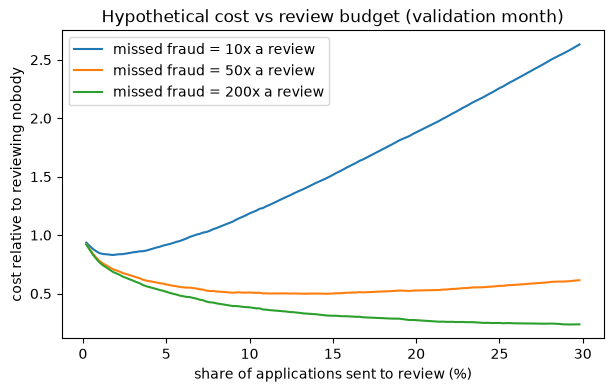

In [11]:
import matplotlib.pyplot as plt

def cost_curve(y, score, ratios, budgets):
    """Cost in 'review units': one manual review = 1 unit, one missed fraud = R units."""
    y = np.asarray(y)
    ys = y[np.argsort(-score)]
    n, n_fraud = len(ys), ys.sum()
    cum_tp = np.cumsum(ys)
    rows = []
    for b in budgets:
        k = int(round(b * n))
        tp = cum_tp[k - 1] if k > 0 else 0
        missed = n_fraud - tp
        for R in ratios:
            rows.append(dict(
                ratio=R, budget=b,
                flagged_per_1000=k / n * 1000,
                recall=tp / n_fraud,
                precision=tp / k if k else np.nan,
                cost_per_1000=(k + missed * R) / n * 1000,
                cost_no_review_per_1000=n_fraud * R / n * 1000,
            ))
    return pd.DataFrame(rows)

ratios = [10, 50, 200]
budgets = np.arange(0.002, 0.30, 0.002)
curve = cost_curve(valid[LABEL], scores["hgb_no_age"], ratios, budgets)

best = curve.loc[curve.groupby("ratio")["cost_per_1000"].idxmin()].copy()
best["cost_reduction_vs_no_review"] = 1 - best["cost_per_1000"] / best["cost_no_review_per_1000"]
print(best[["ratio", "budget", "flagged_per_1000", "recall", "precision",
            "cost_per_1000", "cost_no_review_per_1000", "cost_reduction_vs_no_review"]]
      .round(3).to_string(index=False))

# what happens at a fixed analyst capacity of 5% of applications
cap = curve[np.isclose(curve["budget"], 0.05)]
print("\nAt a 5% review capacity:")
print(cap[["ratio", "flagged_per_1000", "recall", "precision", "cost_per_1000",
           "cost_no_review_per_1000"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for R in ratios:
    c = curve[curve["ratio"] == R]
    ax.plot(c["budget"] * 100, c["cost_per_1000"] / c["cost_no_review_per_1000"], label=f"missed fraud = {R}x a review")
ax.set_xlabel("share of applications sent to review (%)")
ax.set_ylabel("cost relative to reviewing nobody")
ax.set_title("Hypothetical cost vs review budget (validation month)")
ax.legend(); plt.show()

In [12]:
s = scores["hgb_no_age"]
cal = pd.DataFrame({"score": s, "fraud": valid[LABEL].to_numpy()})
cal["bin"] = pd.qcut(cal["score"].rank(method="first"), 10, labels=False)
print(cal.groupby("bin").agg(rows=("fraud", "size"), mean_predicted=("score", "mean"),
                             observed_fraud_rate=("fraud", "mean")).round(4))

      rows  mean_predicted  observed_fraud_rate
bin                                            
0    11933          0.0005               0.0002
1    11932          0.0008               0.0003
2    11932          0.0012               0.0008
3    11932          0.0016               0.0012
4    11933          0.0021               0.0018
5    11932          0.0029               0.0035
6    11932          0.0040               0.0049
7    11932          0.0061               0.0096
8    11932          0.0112               0.0180
9    11933          0.0573               0.0780


In [13]:
older_valid = (valid["customer_age"] >= 50).to_numpy()
print(group_report(valid[LABEL], scores["hgb_no_age"], older_valid, budget=0.05).to_string(index=False))

      group  rows  fraud_rate  flagged_share  false_positive_rate  recall
   under 50 98598      0.0095         0.0403               0.0364  0.4453
50 and over 20725      0.0227         0.0960               0.0837  0.6277
